# Notebook 02: Raw Eye-Tracking Feature Extraction (Revision 12)
Examines raw recording workbooks from the Tobii Pro Fusion eye tracker and demonstrates extraction of the **11 canonical baseline predictors**:
1. `valid_sample_ratio`: Eye-tracker validity ratio
2. `early_window_sample_count`: Samples acquired in 0–500 ms
3. `early_probe_fix_dur`: Probe fixation duration (0–500 ms)
4. `early_irrel_fix_dur`: Irrelevant control fixation duration (0–500 ms)
5. `early_probe_diff`: Early orienting dwell difference
6. `mid_probe_diff`: Intermediate appraisal dwell difference (500–1000 ms)
7. `late_probe_diff`: Late exploration dwell difference (1000–2000 ms)
8. `total_probe_diff`: Full trial dwell difference (0–7500 ms)
9. `mean_fix_duration`: Mean fixation duration
10. `median_fix_duration`: Median fixation duration
11. `fixation_count`: Fixation event count

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"E:\karthianna\data\processed\zenodo_features.csv")
features = [
    "valid_sample_ratio", "early_window_sample_count", "early_probe_fix_dur",
    "early_irrel_fix_dur", "early_probe_diff", "mid_probe_diff", "late_probe_diff",
    "total_probe_diff", "mean_fix_duration", "median_fix_duration", "fixation_count"
]

print("11 Evaluated Baseline Predictors Summary Statistics:")
print(df[features].describe().round(2).T[['count', 'mean', 'std', 'min', '50%', 'max']])

11 Evaluated Baseline Predictors Summary Statistics:
                           count     mean      std      min      50%       max
valid_sample_ratio         819.0     0.79     0.22     0.15     0.87      1.00
early_window_sample_count  819.0   124.25    10.27    61.00   126.00    126.00
early_probe_fix_dur        819.0    79.75   182.57     0.00     0.00    949.62
early_irrel_fix_dur        819.0    68.22    81.36     0.00    11.11    349.86
early_probe_diff           819.0    11.53   222.95  -349.86     0.00    949.62
mid_probe_diff             819.0    -3.61   293.40  -347.08   -24.99   1041.25
late_probe_diff            819.0    -3.33   507.38  -694.17   -49.98   2024.19
total_probe_diff           819.0   -17.29  1688.35 -4848.06  -127.73  11298.26
mean_fix_duration          819.0   507.89   505.08    68.00   376.19   6671.27
median_fix_duration        819.0   463.07   645.14    68.00   320.00   9476.00
fixation_count             819.0  1197.66   450.28    17.00  1368.00   1810.00

<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


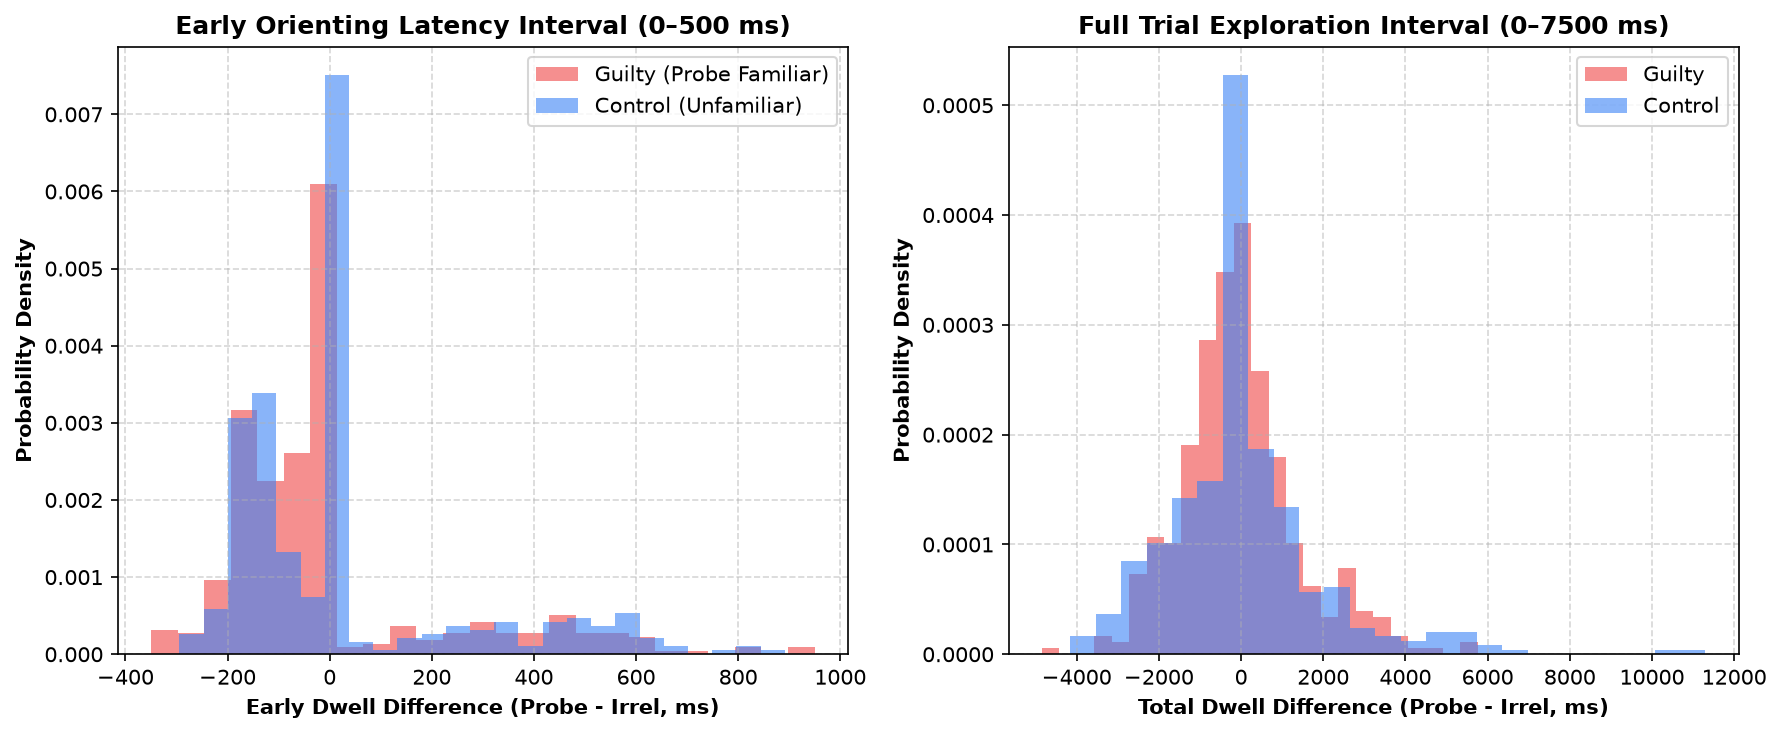

In [2]:
# Visualizing Early Orienting Divergence vs Full-Trial Divergence
guilty = df[df['familiarity_label'] == 1]
control = df[df['familiarity_label'] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Early Window (0-500 ms)
axes[0].hist(guilty['early_probe_diff'], bins=25, alpha=0.6, label='Guilty (Probe Familiar)', color='#EF4444', density=True)
axes[0].hist(control['early_probe_diff'], bins=25, alpha=0.6, label='Control (Unfamiliar)', color='#3B82F6', density=True)
axes[0].set_xlabel('Early Dwell Difference (Probe - Irrel, ms)', fontweight='bold')
axes[0].set_ylabel('Probability Density', fontweight='bold')
axes[0].set_title('Early Orienting Latency Interval (0–500 ms)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Full Trial (0-7500 ms)
axes[1].hist(guilty['total_probe_diff'], bins=25, alpha=0.6, label='Guilty', color='#EF4444', density=True)
axes[1].hist(control['total_probe_diff'], bins=25, alpha=0.6, label='Control', color='#3B82F6', density=True)
axes[1].set_xlabel('Total Dwell Difference (Probe - Irrel, ms)', fontweight='bold')
axes[1].set_ylabel('Probability Density', fontweight='bold')
axes[1].set_title('Full Trial Exploration Interval (0–7500 ms)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()